Dataset:


,StudyHours,Attendance,Passed
0,1.0,55,0
1,1.5,60,0
2,2.0,62,0
3,2.5,65,0
4,3.0,68,1
5,3.2,70,1
6,3.5,72,1
7,4.0,75,1
8,4.2,78,1
9,4.5,80,1


Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


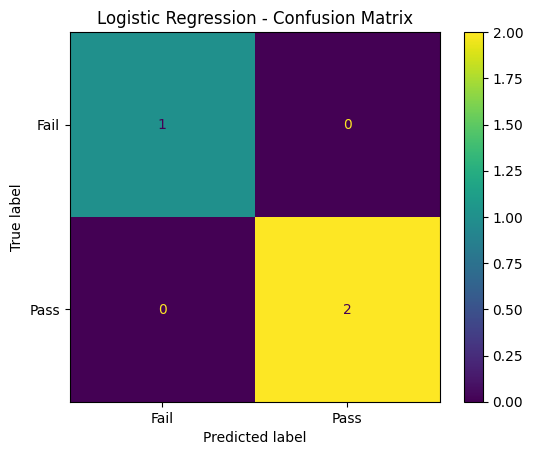

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

data = pd.DataFrame({
    "StudyHours": [1.0, 1.5, 2.0, 2.5, 3.0, 3.2, 3.5, 4.0, 4.2, 4.5, 5.0, 5.5],
    "Attendance": [55, 60, 62, 65, 68, 70, 72, 75, 78, 80, 82, 85],
    "Passed": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
})

print("Dataset:")
display(data)

X = data[["StudyHours", "Attendance"]]
y = data["Passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail", "Pass"]).plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, zero_division=0))